# EMNIST Letter Classifier - Demo

Checks image orientation and label mapping, then shows predictions from the trained model on random test images.

Run from the repo root after `python -m src.train` (or download `best.pt` from the Releases page into `checkpoints/`).

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import matplotlib.pyplot as plt
import torch
from src.data import CLASSES, get_datasets
from src.evaluate import get_device, load_model

train, val, test = get_datasets()
print(f"train {len(train):,} | val {len(val):,} | test {len(test):,}")

train 112,320 | val 12,480 | test 20,800


## Orientation and labels

Raw EMNIST images are stored transposed and labels run 1-26. `src/data.py` transposes each image and shifts labels to 0-25, so these should read upright with matching letters.

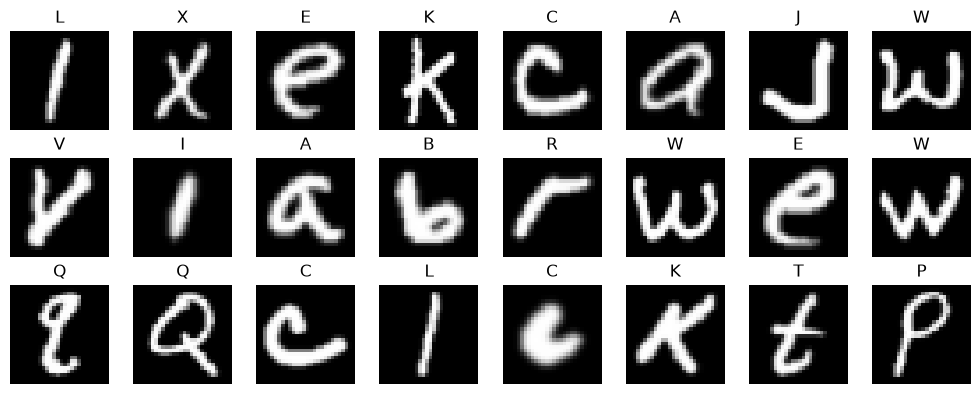

In [2]:
fig, axes = plt.subplots(3, 8, figsize=(10, 4))
for ax, i in zip(axes.flat, range(24)):
    img, label = train[i]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(CLASSES[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

## Predictions on random test images

Red titles mark mistakes.

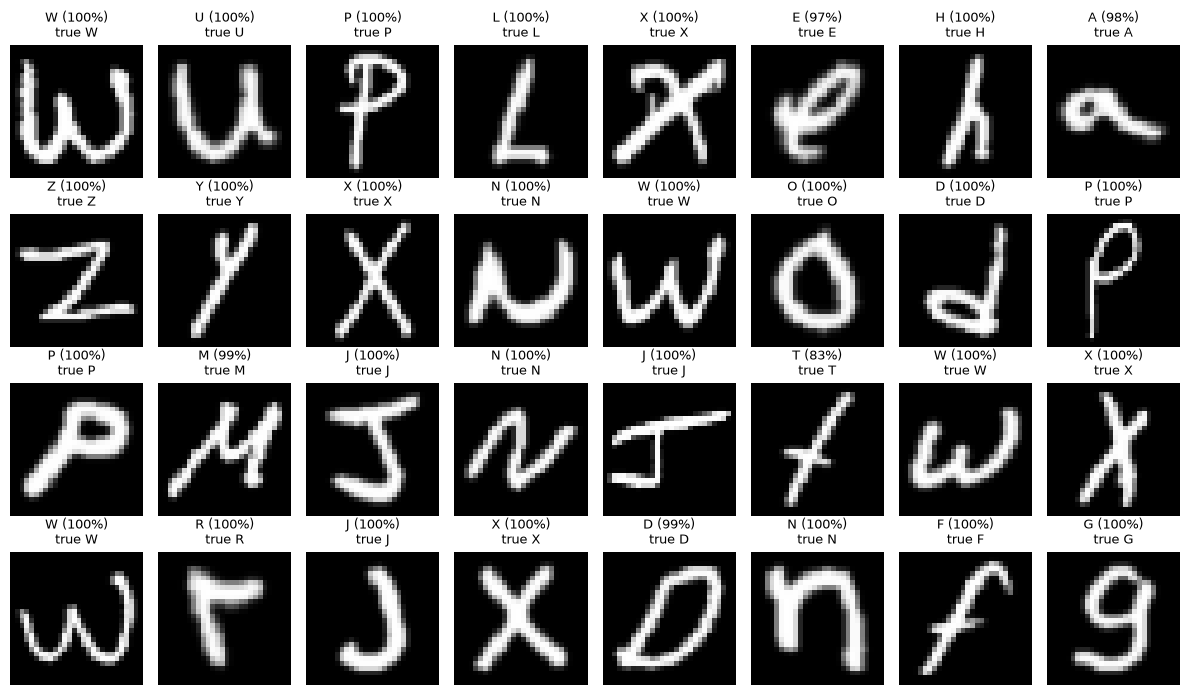

32/32 correct


In [3]:
device = get_device()
model = load_model("checkpoints/best.pt", device)

g = torch.Generator().manual_seed(0)
idx = torch.randint(len(test), (32,), generator=g).tolist()
x = torch.stack([test[i][0] for i in idx])
y = [test[i][1] for i in idx]
with torch.no_grad():
    probs = model(x.to(device)).softmax(1).cpu()
conf, pred = probs.max(1)

fig, axes = plt.subplots(4, 8, figsize=(12, 7))
for ax, img, t, p, c in zip(axes.flat, x, y, pred.tolist(), conf.tolist()):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"{CLASSES[p]} ({c:.0%})\ntrue {CLASSES[t]}", fontsize=9,
                 color="black" if p == t else "red")
    ax.axis("off")
plt.tight_layout()
plt.show()
print(f"{sum(p == t for p, t in zip(pred.tolist(), y))}/{len(y)} correct")